# 10 — Learning from parking counts without seeing the future

Imagine noting the number of empty spaces every half hour. **Persistence** means predicting the last count again. A learned predictor must beat that simple comparison on the **same later readings**.

This lesson reads completed **historical development** results. It does not train, acquire data, issue predictions, call the final scorer, or open raw/growing/final observations. The study's future result is deliberately not loaded, even when this notebook is opened later. Python/Jupyter execution and cached figures are not proof of student understanding or operation on a new offline computer.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display, HTML
ROOT = Path.cwd()
if not (ROOT / 'src/smart_parking').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src/smart_parking').is_dir(), 'Open this notebook from the project folder.'
sys.path.insert(0, str(ROOT / 'src'))
from smart_parking.singapore_lesson import load_lesson, teaching_prediction, plot_development, table_html
def show_table(rows):
    display(HTML(table_html(rows)))
lesson = load_lesson(ROOT)
print(lesson['scope'])
print('Source:', lesson['source_id'], '|', lesson['licence'])
print('Final result:', lesson['actual_final_result'])

Completed DEVELOPMENT evidence only; no new real evaluation
Source: SRC-LIVE-001 | Singapore Open Data Licence 1.0; official data.gov.sg feed under accepted terms
Final result: Not loaded by this lesson


## 1. When did we actually know a count?

A source update time and the laptop's acquisition time are different. A feature must already be available when the forecast is issued. A training target must arrive before the global training cutoff. We keep car parks and lot types separate, require the same capacity, and do not fill gaps with invented counts.

The actual development targets were **27.30–43.01 minutes** after issue, inside the declared 20–45 minute matching window. This is not an exact 30-minute benchmark. Thousands of parking series observed at nine shared times are still only **nine global development times**.

In [2]:
split_table = [
    {'Role': 'Training', 'Windows': lesson['training']['examples'], 'Global times': lesson['training']['global_origin_times'], 'Series': lesson['training']['series']},
    {'Role': 'Development', 'Windows': lesson['development']['examples'], 'Global times': lesson['development']['global_origin_times'], 'Series': lesson['development']['series']},
]
show_table(split_table)
print('Training targets received by:', lesson['training_cutoff'])
print('Historical evidence cutoff:', lesson['historical_cutoff'])

Role,Windows,Global times,Series
Training,18393,18,1355
Development,9202,9,1243


Training targets received by: 2026-10-25T21:27:05.002849+00:00
Historical evidence cutoff: 2026-10-26T07:46:23.970649+00:00


## 2. Try the idea with a synthetic example

The frozen trend model learned one coefficient from training only: approximately **0.30**. If the last half-hour change was +10 spaces, carry about +3 spaces forward. If the previous gap was 15 minutes, first scale its change to a nominal 30-minute change. Keep the result between zero and the car park's capacity.

The calculation below is a **synthetic teaching example**, not a real observation or measured accuracy. You may change the example counts and gap. This does not edit the research checkpoint or refit its coefficient.

In [3]:
previous_count = 40
current_count = 50
past_gap_minutes = 30
capacity = 100
toy = teaching_prediction(previous_count, current_count, past_gap_minutes, capacity, lesson['coefficient'])
show_table([{'Synthetic example': key, 'Value': value} for key, value in toy.items()])
print('Frozen training-only coefficient:', f"{lesson['coefficient']:.9f}")

Synthetic example,Value
data_kind,synthetic_teaching_example
previous,40
current,50
past_gap_minutes,30
projected_30min_change,10
coefficient,0.300185
prediction,53.001852
persistence_prediction,50
actual_future_value,Unknown; no synthetic result is treated as real accuracy


Frozen training-only coefficient: 0.300185185


## 3. Compare the completed development trials

The ridge trial optimized squared error in normalized counts and was rejected. The next trial fitted a constrained weighted median for absolute error in the *unclipped change in space count*, then clipped inference predictions to capacity. It was fitted once, without a development grid.

The trend candidate passed the rules saved before fitting: at least 1% overall MAE gain, no worse average when collection times have equal weight, no individual origin worsening by more than half a space, and physically bounded predictions. **Two collection times still got worse.** A development pass does not guarantee that every car park or future period improves.

The chart recomputes stored error arithmetic on the same 9,202 historical development rows. It is not a new final evaluation, a neural model score, or camera-occupancy accuracy.

Method,Development MAE (spaces),Decision
Last count,6.957618,Comparison
Ridge,7.738379,Rejected
Trend,6.309848,Frozen research candidate


Trend development gain: 9.31%; this is not a live/final accuracy claim.


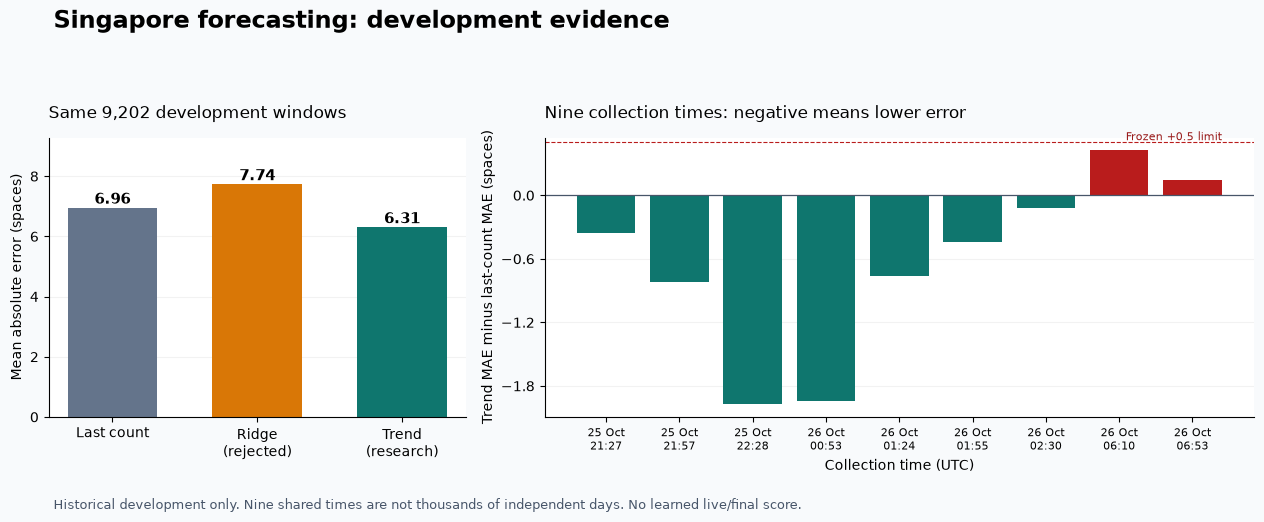

In [4]:
comparison = [
    {'Method': 'Last count', 'Development MAE (spaces)': lesson['maes']['persistence_error'], 'Decision': 'Comparison'},
    {'Method': 'Ridge', 'Development MAE (spaces)': lesson['maes']['ridge_error'], 'Decision': 'Rejected'},
    {'Method': 'Trend', 'Development MAE (spaces)': lesson['maes']['trend_error'], 'Decision': 'Frozen research candidate'},
]
show_table(comparison)
print(f"Trend development gain: {lesson['relative_development_gain']:.2%}; this is not a live/final accuracy claim.")
figure = plot_development(lesson)
plt.show()

## 4. Missing targets are not perfect predictions

Suppose ten forecasts were issued and only eight later targets arrived. If those eight absolute errors sum to 16 spaces, their observed MAE is **16 / 8 = 2 spaces**, and matching coverage is **8 / 10 = 80%**. Dividing by ten would pretend the two missing errors were zero.

This is synthetic arithmetic. In the real planned test, learned and last-count errors must use exactly the same matched forecast IDs. The first received qualifying target is used; a later reading cannot be chosen just because it gives a better score. A fresh capacity change stops matching.

In [5]:
issued_teaching = 10
observed_errors_teaching = [1, 3, 2, 2, 1, 3, 2, 2]
matched_teaching = len(observed_errors_teaching)
print('SYNTHETIC coverage:', f'{matched_teaching / issued_teaching:.0%}')
print('SYNTHETIC observed MAE:', sum(observed_errors_teaching) / matched_teaching, 'spaces')
print('Missing errors: unknown, not zero')

SYNTHETIC coverage: 80%
SYNTHETIC observed MAE: 2.0 spaces
Missing errors: unknown, not zero


## 5. The sealed prospective study

Before any fitting, all car parks were reserved globally for forecast origins from **26 October 2026, 10:00 UTC to 27 October, 10:00 UTC** (India: 15:30 to 15:30). Candidate, issuer, scoring code and matching gates were frozen before that period.

No final scoring is permitted before **27 October, 10:51 UTC** (India: 16:21). Actual predictions need pre-target batch receipts bound to the original acquisition receipts and checkpoint. The final scorer consumes the whole source interval before reading target values; failure does not reopen it. Repeated commands may display archived completed results, but cannot run changed methods again.

This lesson deliberately does not fetch status or outcomes from growing data. Read the dated operations guide for collection/scoring commands; do not paste them into this teaching notebook.

In [6]:
print('Reserved origin interval:', *lesson['final_origins'], sep='\n  ')
print('Final scoring allowed only after:', lesson['final_closure'])
print('Scoring implementation frozen at:', lesson['scoring_frozen_at'])
show_table([{'Frozen final rule': key, 'Value': value} for key, value in lesson['final_gate'].items()])
print('Final result:', lesson['actual_final_result'])

Reserved origin interval:
  2026-10-26T10:00:00+00:00
  2026-10-27T10:00:00+00:00
Final scoring allowed only after: 2026-10-27T10:51:00+00:00
Scoring implementation frozen at: 2026-10-26T08:53:02.865655+00:00


Frozen final rule,Value
min_matched_forecasts,500
min_global_matched_origins,8
min_matched_series,50
min_matched_fraction_of_resolved_forecasts,0.75
raw_mae_relative_improvement_min,0.01
macro_origin_mae_noninferior,True
max_each_origin_mae_regression_spaces,0.5
no_score_before,2026-10-27T10:51:00+00:00


Final result: Not loaded by this lesson


## Explain it in your own words

1. Why must acquisition time be checked as well as the source update time?
2. Why are 9,202 windows at nine shared times not 9,202 independent days?
3. What would happen to the synthetic prediction if the past gap changed from 30 to 15 minutes?
4. Why can the average improve while two collection times get worse?
5. Why must missing targets stay unknown, and both methods use the same matched IDs?
6. What can this aggregate-count study tell us about a vehicle detector? Why is the Birmingham LSTM a separate result?

**Student explanations have not been assessed.** Do not claim mastery from notebook execution.

Provenance: official [Singapore availability feed](https://api.data.gov.sg/v1/transport/carpark-availability), SRC-LIVE-001, Singapore Open Data Licence 1.0 under accepted terms. Stored raw data and receipts remain separate from the two explicitly synthetic examples. See `docs/SINGAPORE_FORECAST_STUDY.md`.

In [7]:
import json
LESSON_CHECKS = dict(paired_development_windows=lesson['paired_windows'], global_development_times=lesson['global_development_times'],
    training_windows=lesson['training']['examples'], ridge_mae=lesson['maes']['ridge_error'], trend_mae=lesson['maes']['trend_error'],
    same_cohort_persistence_mae=lesson['maes']['persistence_error'], input_hashes=lesson['input_hashes'],
    actual_final_result_loaded=False, model_trained=False, real_data_acquired=False, student_mastery_assessed=False,
    synthetic_example_prediction=toy['prediction'], synthetic_missing_errors_are_unknown=True)
print('LESSON_CHECKS=' + json.dumps(LESSON_CHECKS, sort_keys=True))

LESSON_CHECKS={"actual_final_result_loaded": false, "global_development_times": 9, "input_hashes": {"data/manifests/singapore_forecast_reservation_v1.json": "bd47defbec2e4e73388b4eb4ad8dd8d04528a04df15ae78242427ca93f5afaca", "data/manifests/singapore_trend_frozen_selection_v1.json": "78dcb60c77e3dab2556365cc01b86740b6be5366ea0eb7cb0925ace65c3e6572", "data/manifests/singapore_trend_issuance_v1.json": "b68cf781fea32a16ee3d05914ff17c325bdd5594bec92f538811a1e711ac9625", "data/manifests/singapore_trend_scoring_v1.json": "1dc86326f3152ca090572041434e057980e151ee75ea4a2b8292f4385cb3aa1b", "experiments/results/SG-HISTORY-20261026T074623970649Z/run.json": "743b05281a0cd8ca1c2b44d49ea278c69812db3974cf1e5c559297439acbfaf9", "experiments/results/SG-LAD-20261026T081112980974Z/model.json": "b11dd08ff444affb92de3841a23ef6de0b63833d270f748df4ff654426e1851f", "experiments/results/SG-LAD-20261026T081112980974Z/observations.csv": "6a343e4836ae97842a9aafcd3ed70427aad82b1a656e1befac2b4f2d1e0202e2", "experi